In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display

In [2]:
width = 900
height = 600

real = np.linspace(-2.5, 1.0, width)
imaginary = np.linspace(-1.0, 1.0, height)

c = real[np.newaxis, :] + 1j * imaginary[:, np.newaxis]

z = np.zeros(c.shape, dtype=complex)
iterations = np.zeros(c.shape, dtype=int)

print("Grid shape:", c.shape)

Grid shape: (600, 900)


In [3]:
max_iter = 120

z = np.zeros(c.shape, dtype=complex)
iterations = np.zeros(c.shape, dtype=int)
active = np.ones(c.shape, dtype=bool)

for i in range(max_iter):
    z[active] = z[active] ** 2 + c[active]

    escaped = np.abs(z) > 2
    newly_escaped = active & escaped

    iterations[newly_escaped] = i + 1
    active[newly_escaped] = False

iterations[active] = max_iter

print("Mandelbrot calculations completed!")

Mandelbrot calculations completed!


In [4]:
real_zoom = np.linspace(-0.77, -0.71, 900)
imag_zoom = np.linspace(0.07, 0.11, 600)

c_zoom = (
    real_zoom[np.newaxis, :]
    + 1j * imag_zoom[:, np.newaxis]
)

z_zoom = np.zeros(c_zoom.shape, dtype=complex)
zoom_iterations = np.zeros(c_zoom.shape, dtype=int)
active_zoom = np.ones(c_zoom.shape, dtype=bool)

for i in range(300):
    z_zoom[active_zoom] = (
        z_zoom[active_zoom] ** 2 + c_zoom[active_zoom]
    )

    escaped = np.abs(z_zoom) > 2
    newly_escaped = active_zoom & escaped

    zoom_iterations[newly_escaped] = i + 1
    active_zoom[newly_escaped] = False

zoom_iterations[active_zoom] = 300

print("Zoom calculation completed!")

Zoom calculation completed!


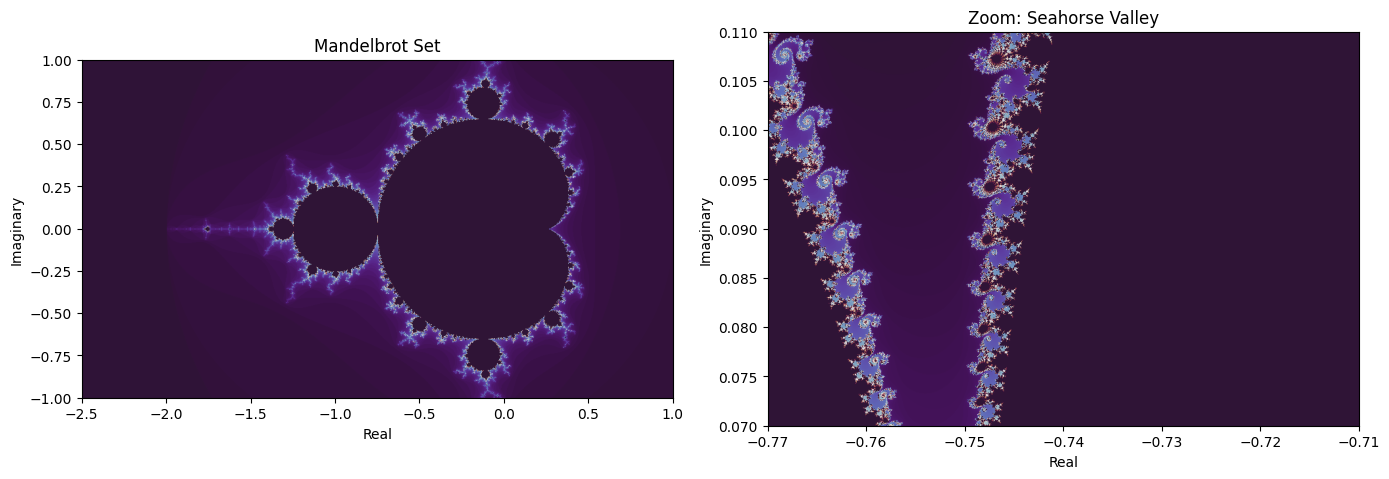

Saved mandelbrot.png


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(
    iterations,
    extent=[-2.5, 1.0, -1.0, 1.0],
    origin="lower",
    cmap="twilight_shifted"
)
axes[0].set_title("Mandelbrot Set")
axes[0].set_xlabel("Real")
axes[0].set_ylabel("Imaginary")

axes[1].imshow(
    zoom_iterations,
    extent=[-0.77, -0.71, 0.07, 0.11],
    origin="lower",
    cmap="twilight_shifted"
)
axes[1].set_title("Zoom: Seahorse Valley")
axes[1].set_xlabel("Real")
axes[1].set_ylabel("Imaginary")

plt.tight_layout()
plt.savefig("mandelbrot.png", dpi=150, bbox_inches="tight")
plt.show()

print("Saved mandelbrot.png")

In [6]:
rows = 60
cols = 90

rng = np.random.default_rng(42)

grid = (rng.random((rows, cols)) < 0.25).astype(int)

print("Grid shape:", grid.shape)
print("Living cells at start:", int(grid.sum()))

Grid shape: (60, 90)
Living cells at start: 1394


In [7]:
def count_neighbours(grid):
    neighbours = np.zeros_like(grid)

    for dr in (-1, 0, 1):
        for dc in (-1, 0, 1):
            if dr == 0 and dc == 0:
                continue

            neighbours += np.roll(
                np.roll(grid, dr, axis=0),
                dc, axis=1
            )

    return neighbours


def next_generation(grid):
    neighbours = count_neighbours(grid)

    survive = (grid == 1) & (
        (neighbours == 2) | (neighbours == 3)
    )

    born = (grid == 0) & (neighbours == 3)

    return (survive | born).astype(int)

In [8]:
generations = 80

history = [grid.copy()]
living_counts = [int(grid.sum())]

for i in range(generations):
    grid = next_generation(grid)

    history.append(grid.copy())
    living_counts.append(int(grid.sum()))

print("Starting living cells:", living_counts[0])
print("Living cells after 80 generations:", living_counts[-1])
print("Total saved grids:", len(history))

Starting living cells: 1394
Living cells after 80 generations: 391
Total saved grids: 81


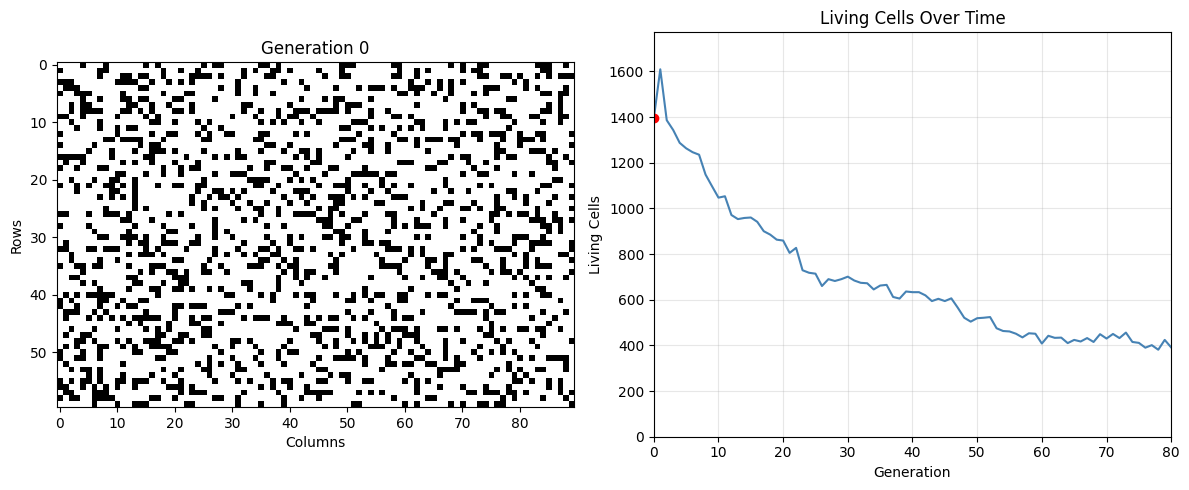

In [9]:
fig, (ax_grid, ax_count) = plt.subplots(1, 2, figsize=(12, 5))

image = ax_grid.imshow(
    history[0],
    cmap="binary",
    interpolation="nearest",
    vmin=0,
    vmax=1
)

ax_grid.set_title("Generation 0")
ax_grid.set_xlabel("Columns")
ax_grid.set_ylabel("Rows")

ax_count.plot(
    range(len(living_counts)),
    living_counts,
    color="steelblue"
)

marker, = ax_count.plot(
    [0], [living_counts[0]], "ro"
)

ax_count.set_title("Living Cells Over Time")
ax_count.set_xlabel("Generation")
ax_count.set_ylabel("Living Cells")
ax_count.set_xlim(0, generations)
ax_count.set_ylim(0, max(living_counts) * 1.1 + 1)
ax_count.grid(True, alpha=0.3)


def animate(frame):
    image.set_data(history[frame])
    ax_grid.set_title(f"Generation {frame}")

    marker.set_data(
        [frame],
        [living_counts[frame]]
    )

    return image, marker


animation = FuncAnimation(
    fig,
    animate,
    frames=len(history),
    interval=1000 / 12,
    blit=False
)

plt.tight_layout()

In [10]:
animation.save(
    "game_of_life.gif",
    writer=PillowWriter(fps=12)
)

plt.close(fig)

print("Saved game_of_life.gif")
print("Frames:", len(history))
print("FPS: 12")

Saved game_of_life.gif
Frames: 81
FPS: 12


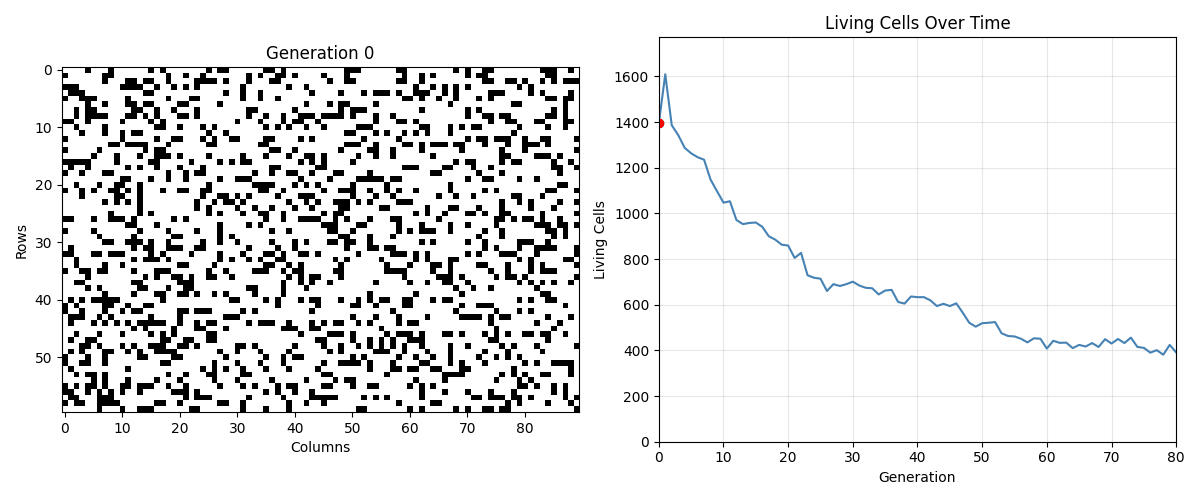

In [11]:
display(Image(filename="game_of_life.gif"))

In [12]:
from google.colab import files

files.download("mandelbrot.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
files.download("game_of_life.gif")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>